Groupe :\
Elisa Borrellarochette\
Léonard Ribon\
Lisa Murcia

## Introduction

Ces dernières années ont été marquées par une intensification des tensions commerciales entre les États-Unis et plusieurs de leurs partenaires, notamment la Chine. Les hausses de droits de douane et les mesures de rétorsion ont contribué à une dynamique de guerre commerciale, particulièrement visible au printemps 2025. On peut en effet distinguer trois périodes, un niveau faible et stable de 2010 à 2017, suivi d'un retour d'un protectionnisme ciblé jusqu'à 2024, pour finir par une flambée historique et impactante en 2025.

Les droits de douane constituent un instrument de politique commerciale important, qui peut modifier le coût des marchandises importées et affecter les échanges entre pays. Nous souhaitons donc étudier l'évolution des droits de douane et du commerce international des États-Unis avec leurs partenaires au fil du temps. Notre but est d'observer dans quelle mesure l’évolution des droits de douane effectifs est associée à celle des importations américaines, et si cette relation diffère selon les partenaires commerciaux.


Notre démarche comporte trois étapes. Nous présentons d’abord la collecte, le nettoyage et l’assemblage des données. Nous explorons ensuite l’évolution des droits de douane et des importations à travers des statistiques descriptives et des cartes dynamiques. Enfin, nous mobilisons une approche en différences de différences pour comparer l’évolution des importations de partenaires ayant connu des hausses de droits de douane d’ampleur différente. Une seconde spécification intègre des caractéristiques des partenaires, notamment des indicateurs économiques issus de la Banque mondiale.

## Import et téléchargement des packages

Dans un premier temps on importe et télécharge au besoin les packages requis à l'execution du notbook.

In [51]:
import importlib
import importlib.util
import subprocess
import sys

# Packages nécessaires : nom du module -> nom du package à installer avec pip
packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "scipy": "scipy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "plotly": "plotly",
    "country_converter": "country_converter",
    "statsmodels": "statsmodels",
    "wbgapi": "wbgapi",
    "tqdm": "tqdm",
}

# Installation des packages qui manquent sur l'ordinateur
manquants = [pip for module, pip in packages.items() if importlib.util.find_spec(module) is None]
if manquants:
    print("Installation de :", ", ".join(manquants))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *manquants])
    importlib.invalidate_caches()
else:
    print("Tous les packages sont déjà installés.")

# Import de tous les packages
import logging
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import country_converter as coco
import statsmodels.formula.api as smf
import wbgapi as wb
from scipy import stats
from tqdm import tqdm

Tous les packages sont déjà installés.


## Collecte et préparation des données

Les données utilisées proviennent de [l’API du United States Census Bureau](https://www.census.gov/data/developers/data-sets/international-trade.html) . Il s’agit de séries temporelles mensuelles portant sur les échanges de marchandises entre les États-Unis et leurs partenaires commerciaux, de janvier 2010 à décembre 2025, soit 192 mois.

Plus précisément, chaque ligne correspond à un partenaire commercial et à un mois, toutes catégories de produits confondues. La base contient les montants des importations générales, des importations pour consommation, des droits de douane calculés sur ces dernières et des exportations.


La préparation comporte quatres étapes :

1. [Demander une clé API](https://api.census.gov/data/key_signup.html)
2. Télécharger et assembler les données mensuelles d’importations dans le script [download_importations_pays_mois.py](<Importation des données/download_importations_pays_mois.py>)
3. Télécharger et assembler les données mensuelles d’exportations dans le script [download_exportations_pays_mois.py](<Importation des données/download_exportations_pays_mois.py>)
4. Réunir ces deux bases et former le fichier csv final dans le script [construction_dataset_commerce_usa_mois.py](<Importation des données/construction_dataset_commerce_usa_mois.py>)

Le téléchargement des différents fichiers csv se fait dans un dossier data exclu du dépôt GitHub. La base finale est conservée sur le stockage S3 de SSP Cloud et accessible par un lien public. Le notebook charge directement ce fichier, sans relancer les requêtes auprès du Census Bureau.
Les scripts sont conservés dans le dépôt, la reconstruction restant donc possible.




### Récupération des données

Les données sont récupérées à partir de deux points d’accès de l’API du U.S. Census Bureau : l’un pour les [importations](https://api.census.gov/data/timeseries/intltrade/imports/hs) et l’autre pour les [exportations](https://api.census.gov/data/timeseries/intltrade/exports/hs).

- [Dictionnaire des variables d’importations](https://api.census.gov/data/timeseries/intltrade/imports/hs/variables.html)
- [Dictionnaire des variables d’exportations](https://api.census.gov/data/timeseries/intltrade/exports/hs/variables.html)

Pour chaque requête, nous récupérons le mois, les variables souhaitées et une clé API saisie au lancement du script. Le paramètre `SUMMARY_LVL="DET"` permet de sélectionner les données à l'échelle des pays partenaires plutôt qu'à l'échelle des groupes de pays.

Pour les importations, nous récupérons les variables :
- `GEN_VAL_MO` : Valeur des importations générales des Etats-Unis depuis le partenaire, pendant le mois en dollars
- `CON_VAL_MO` : Valeur des importations pour consommation sur le marché américain, pendant le mois, en dollars
- `CAL_DUT_MO` : Montant des droits de douane calculés sur les importations pour consommation, en dollars

Pour les exportations, nous récupérons la variable `ALL_VAL_MO` représentant la valeur totale des exportations des Etats-Unis vers le partenaire, pendant le mois, en dollars.

Chaque ligne de données contient également le code et le nom du partenaire.

Après un premier essai sur janvier 2010 pour vérifier qu'aucun problème n'apparaît, une boucle parcourt les mois suivants jusqu’à décembre 2025. Chaque réponse est transformée en tableau avec pandas, puis enregistrée dans un CSV nommé de la forme suivante : `imports_année_mois.csv` pour les importations et `exports_année_mois.csv` pour les exportations. 


- Le code associé aux importations se trouve dans le fichier [download_importations_pays_mois.py](<Importation des données/download_importations_pays_mois.py>).
- Le code associé aux exportations se trouve dans le fichier [download_exportations_pays_mois.py](<Importation des données/download_exportations_pays_mois.py>).

Extrait du code pour les importations : 
```python
periode = "2010-01"

parametres = {            # paramètres du dictionnaire indiqué sur le site Census
    "time": periode,
    "key": cle_api,
    "get": "CTY_CODE,CTY_NAME,GEN_VAL_MO,CON_VAL_MO,CAL_DUT_MO",     # importation des colonnes
    "SUMMARY_LVL": "DET"     # importation des pays individuellement
    }

reponse = requests.get(url_imports, params=parametres)
print(reponse.status_code)      # si sortie 200, signifie que le serveur a répondu avec succès
data = reponse.json()
```

### Assemblage des fichiers mensuels

Toujours dans [download_importations_pays_mois.py](<Importation des données/download_importations_pays_mois.py>) et [download_exportations_pays_mois.py](<Importation des données/download_exportations_pays_mois.py>), pour chaque flux, nous vérifions que les fichiers correspondant aux 192 mois attendus sont présents. Si un fichier manque, le programme s’arrête et indique les mois concernés.

Les CSV mensuels sont ensuite lus avec pandas et réunis par concaténation : leurs lignes sont ajoutées les unes à la suite des autres.

Cette étape produit deux fichiers couvrant toute la période : `importations_usa_2010_2025.csv` et `exportations_usa_2010_2025.csv`.

Extrait du code pour les importations : 
```python
all_tables = []

for periode in periodes:              # On crée un tableau de tableau avec les données de chaque mois
    file = dossier_data / f"imports_{periode}.csv"
    table = pd.read_csv(file, dtype={"CTY_CODE" : str})
    all_tables.append(table)

print(len(all_tables))

importations_usa = pd.concat(all_tables, ignore_index = True)     # Concaténation dans un seul grand tableau (empiler les lignes)
print(importations_usa.shape)
```

### Construction de la base finale

Dans [construction_dataset_commerce_usa_mois.py](<Importation des données/construction_dataset_commerce_usa_mois.py>), après avoir vérifié qu’il n'y a pas de doublons de lignes pour un même couple partenaire-mois dans nos 2 dataset créés, on utilise le code du partenaire (`CTY_CODE`) et le mois (`time`) afin de réunir les deux bases en une seule.

Nous effectuons une jointure afin de conserver les couples présents dans au moins une des deux bases. Lorsqu’un couple figure uniquement dans les importations ou dans les exportations, les montants provenant de l’autre source restent manquants.

Extrait du code : 
```python
commerce_usa = imports.merge(exports, on = ["CTY_CODE", "time"], how="outer", suffixes=("_imports", "_exports"), validate="one_to_one", indicator=True)
```

Nous procédons ensuite à un nettoyage de la base afin d'avoir un fichier final propre. Nous construisons une seule colonne de noms en utilisant celui des importations lorsqu’il est disponible, puis celui des exportations sinon. Certaines observations restent sans nom et correspondent au code 8220. Nous leur attribuons le libellé « Pays non identifiés ». 

Nous supprimons ensuite les anciennes colonnes de noms et l’indicateur de jointure, utilisé pour les vérifications afin de garder seulement les colonnes strictement nécessaires pour l'analyse. Les variables de montants sont renommées pour faciliter leur lecture.

La base finale est enregistrée dans le fichier `commerce_usa_2010_2025.csv`. Chaque ligne correspond à un couple partenaire–mois. Il contient les colonnes suivantes :
- `CTY_CODE` : Code Census du partenaire commercial 
- `CTY_NAME` : Nom du partenaire commercial 
- `time` : Mois et année au format YYYY-MM
- `importations_generales` : Valeur des importations générales des États-Unis depuis le partenaire en USD 
- `importations_consommation` : Valeur des importations mises à disposition du marché américain en USD 
- `droits_douane` : Montant des droits de douane calculés sur les importations pour consommation en USD 
- `exportations` : Valeur totale des exportations des États-Unis vers le partenaire en USD 

Les montants sont mensuels, exprimés en dollars américains courants, et regroupent toutes les catégories de produits. 

### Chargement et vérification de la base finale

Nous chargeons la base sauvegardée sans relancer les requêtes à l’API.

In [52]:
url = "https://minio.lab.sspcloud.fr/elisaborrel/diffusion/commerce_usa/commerce_usa_2010_2025.csv"

commerce_usa = pd.read_csv(url, dtype={"CTY_CODE": str})
commerce_usa.head()

,CTY_CODE,CTY_NAME,time,importations_generales,importations_consommation,droits_douane,exportations
0,1010,GREENLAND,2010-01,324 360.00,324 360.00,0.00,215 325.00
1,1010,GREENLAND,2010-02,505 713.00,505 713.00,0.00,1 336 067.00
2,1010,GREENLAND,2010-03,795 702.00,795 702.00,0.00,518 806.00
3,1010,GREENLAND,2010-04,332 034.00,332 034.00,0.00,1 057 409.00
4,1010,GREENLAND,2010-05,391 091.00,391 091.00,0.00,498 422.00


In [53]:
print("Nombre de lignes :", len(commerce_usa))
print("Nombre de colonnes :", commerce_usa.shape[1])

print("Premier mois :", commerce_usa["time"].min())
print("Dernier mois :", commerce_usa["time"].max())
print("Nombre de mois distincts :", commerce_usa["time"].nunique())

print("Nombre de doublons partenaire–mois :",commerce_usa.duplicated(subset=["CTY_CODE", "time"]).sum())

print("Valeurs manquantes:")
commerce_usa.isna().sum()

Nombre de lignes : 44686
Nombre de colonnes : 7
Premier mois : 2010-01
Dernier mois : 2025-12
Nombre de mois distincts : 192
Nombre de doublons partenaire–mois : 0
Valeurs manquantes:


CTY_CODE                       0
CTY_NAME                       0
time                           0
importations_generales       367
importations_consommation    367
droits_douane                367
exportations                 251
dtype: int64

### Statistiques descriptives sur les importations

Avant d'analyser les taux de droits de douane, nous présentons les statistiques descriptives de base des importations générales (importations_generales) sur l'ensemble des 236 partenaires, puis nous traçons l'évolution mensuelle du total des importations américaines (en milliards de dollars) afin de situer la dynamique globale des échanges.

In [54]:
# 3. Statistiques descriptives sur les importations

pd.options.display.float_format = lambda x: f"{x:,.2f}".replace(",", " ")    # permet d'enlever l'écriture scientifique

print("\n" + "=" * 65)
print("STATISTIQUES DESCRIPTIVES : importations_generales (USD)")
print("=" * 65)
print(commerce_usa['importations_generales'].describe().round(2))

nombre_pays = commerce_usa.loc[commerce_usa["importations_generales"] > 0, "CTY_CODE"].nunique()

print("\nNombre de partenaires avec des importations > 0 :", nombre_pays)
print("Nombre de lignes avec importations générales > 0 :", (commerce_usa['importations_generales'] > 0).sum())


STATISTIQUES DESCRIPTIVES : importations_generales (USD)
count           44 319.00
mean       924 662 923.02
std      3 948 787 566.69
min                  0.00
25%            510 940.00
50%         11 267 683.00
75%        272 099 327.50
max     52 081 070 497.00
Name: importations_generales, dtype: float64

Nombre de partenaires avec des importations > 0 : 236
Nombre de lignes avec importations générales > 0 : 43437


Les importations générales se situent entre 0 et 52 081 070 497 dollars. En moyenne, le montant des importations générales est d'environ 924 662 923 dollars. On observe également de gros écarts entre les pays et selon les différentes dates.


Il existe au moins un mois entre 2010 et 2025 où les Etats-Unis n'ont pas importé de marchandises d'un de leur partenaire. On remarque tout de même que tous les partenaires renseignés dans la base de données exportent au moins lors d'un mois vers les USA.


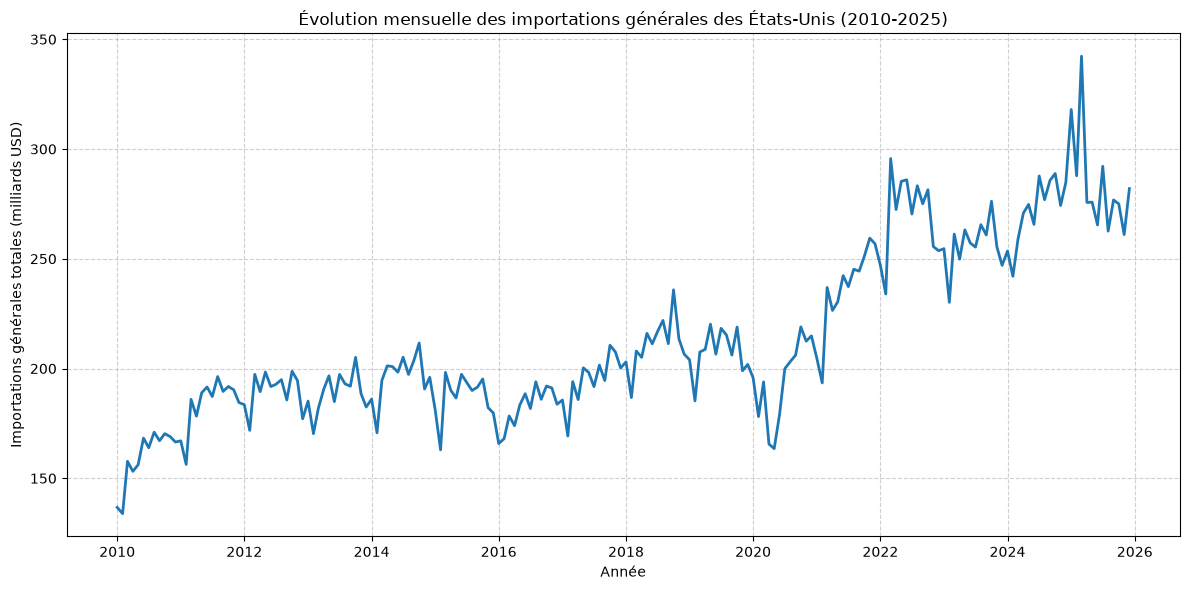

Graphique sauvegardé avec succès sous 'evolution_importations.png' !


In [55]:
# 3bis. Évolution mensuelle des importations générales totales (en milliards d'USD)
commerce_usa['time'] = pd.to_datetime(commerce_usa['time'])
imports_mensuelles = (
    commerce_usa.groupby('time')['importations_generales']
    .sum()
    .reset_index()
)
imports_mensuelles['imports_milliards'] = imports_mensuelles['importations_generales'] / 1e9

plt.figure(figsize=(12, 6))
sns.lineplot(data=imports_mensuelles, x='time', y='imports_milliards', color='#1f77b4', linewidth=2)
plt.title("Évolution mensuelle des importations générales des États-Unis (2010-2025)")
plt.xlabel("Année")
plt.ylabel("Importations générales totales (milliards USD)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("evolution_importations.png", dpi=300, bbox_inches="tight")
plt.show()
print("Graphique sauvegardé avec succès sous 'evolution_importations.png' !")

Début 2010, les importations générales des États-Unis sont à moins de 150 milliards de dollars. Fin 2025, les importations générales des États-Unis sont à environ 275 milliards de dollars.

On remarque une tendance générale à la hausse avec une baisse en 2019 que l'on peut associée au Covid. Puis une augmentation d'autant plus forte une fois la période passée, avec un pique extrêmement important vers 2025 avec des importations générales atteingnant environ 340 milliards de dollars.

### Calcul du taux de droits de douane effectif

À partir du jeu de données `commerce_usa` (44 686 observations couvrant 192 mois, de janvier 2010 à décembre 2025), nous calculons un taux de droits de douane effectif nommé douane_pourcentage ($\frac{\text{droits\_douane}}{\text{importations\_generales}} \times 100$), en sécurisant le calcul contre les divisions par zéro et les valeurs manquantes (NaN). 
Cette colonne servira ensuite à la fois pour l'analyse descriptive et pour la carte dynamique des droits de douane.

In [43]:
# 4. Création sécurisée de la colonne de pourcentage (anti-division par zéro et anti-inf)
commerce_usa['douane_pourcentage'] = 0.0
masque = commerce_usa['importations_generales'] > 0
commerce_usa.loc[masque, 'douane_pourcentage'] = (
    commerce_usa.loc[masque, 'droits_douane'] / commerce_usa.loc[masque, 'importations_generales']
) * 100
commerce_usa['douane_pourcentage'] = commerce_usa['douane_pourcentage'].replace([np.inf, -np.inf], 0).fillna(0)

# 5. Aperçus et vérifications
print("Aperçu avec la colonne douane_pourcentage :")
print(commerce_usa[['CTY_NAME', 'time', 'importations_generales', 'droits_douane', 'douane_pourcentage']].head())

print("\nNombre de lignes avec des droits de douane strictement supérieurs à 0 :",commerce_usa[commerce_usa['droits_douane'] > 0][['CTY_NAME', 'time', 'importations_generales', 'droits_douane', 'douane_pourcentage']].shape)

nombre_pays_douane = commerce_usa.loc[commerce_usa["droits_douane"] > 0, "CTY_CODE"].nunique()
print("Nombre de partenaires avec des droits de douane > 0 :", nombre_pays_douane)



print("\nValeur max des droits de douane :", commerce_usa['droits_douane'].max())



Aperçu avec la colonne douane_pourcentage :
    CTY_NAME       time  importations_generales  droits_douane  \
0  GREENLAND 2010-01-01              324 360.00           0.00   
1  GREENLAND 2010-02-01              505 713.00           0.00   
2  GREENLAND 2010-03-01              795 702.00           0.00   
3  GREENLAND 2010-04-01              332 034.00           0.00   
4  GREENLAND 2010-05-01              391 091.00           0.00   

   douane_pourcentage  
0                0.00  
1                0.00  
2                0.00  
3                0.00  
4                0.00  

Nombre de lignes avec des droits de douane strictement supérieurs à 0 : (36906, 5)
Nombre de partenaires avec des droits de douane > 0 : 235

Valeur max des droits de douane : 10119542817.0


Les valeurs prise par les droits de douane se situe entre 0 et 10 119 542 817 dollars. 

Pour certains pays et périodes, les droits de douane sont égaux à 0. Plus particulièrement, il existe un pays pour lequel les droits de douane sont constamment nuls.

### Distribution et traitement des valeurs aberrantes

Nous examinons d'abord la distribution brute de douane_pourcentage, puis uniquement sur les flux imposés (> 0 %). Quelques observations présentent des taux extrêmement élevés (au-delà de 200 %, soit 6 lignes atypiques dues à de très faibles montants d'importation). Nous isolons ces anomalies pour les inspecter, puis nous filtrons les taux compris entre 0 % et 200 % afin d'obtenir un périmètre propre de 36 898 lignes.

In [48]:
# 6. Statistiques descriptives de la nouvelle colonne
print("\n" + "=" * 65)
print("STATISTIQUES DESCRIPTIVES : douane_pourcentage")
print("=" * 65)
print(commerce_usa['douane_pourcentage'].describe().round(4))

# 6bis. Taux non nuls
commerce_usa_avec_douanes = commerce_usa[commerce_usa['douane_pourcentage'] > 0]
print(f"\nNombre de lignes avec un taux de douane non nul : {len(commerce_usa_avec_douanes)} sur {len(commerce_usa)} total")

print("\n" + "=" * 65)
print("STATISTIQUES DESCRIPTIVES : douane_pourcentage (Taux > 0 %)")
print("=" * 65)
print(commerce_usa_avec_douanes['douane_pourcentage'].describe().round(4))


STATISTIQUES DESCRIPTIVES : douane_pourcentage
count      44 686.00
mean           36.80
std         7 290.57
min             0.00
25%             0.02
50%             0.33
75%             1.59
max     1 540 900.00
Name: douane_pourcentage, dtype: float64

Nombre de lignes avec un taux de douane non nul : 36904 sur 44686 total

STATISTIQUES DESCRIPTIVES : douane_pourcentage (Taux > 0 %)
count      36 904.00
mean           44.56
std         8 022.51
min             0.00
25%             0.10
50%             0.67
75%             1.99
max     1 540 900.00
Name: douane_pourcentage, dtype: float64


Le taux de droits de douane est compris entre 0% et 1 540 900%, ce qui peut être très surprenant. Cependant, en observant les quantiles, on remarque qu'environ 75% des observations ont un taux de droits de douane en dessous de 1,59%.  On a donc des valeurs aberrantes dans les valeurs supérieures, qui tirent la moyenne de 36,8% vers le haut. Par ailleurs, la moitié des observations se situent également au dessous du seuil de 0,33%.

In [50]:
# 6bis'. Taux non nuls et <= 200 %
commerce_usa_filtre = commerce_usa[(commerce_usa['douane_pourcentage'] > 0) & (commerce_usa['douane_pourcentage'] <= 200)]
print(f"Nombre de lignes après nettoyage des anomalies : {len(commerce_usa_filtre)} sur {len(commerce_usa)}")
print("\n" + "=" * 65)
print("STATISTIQUES DESCRIPTIVES : douane_pourcentage (Taux entre 0% et 200%)")
print("=" * 65)
print(commerce_usa_filtre['douane_pourcentage'].describe().round(4))

# 7. Analyse des anomalies (taux strictement supérieur à 200 %)
anomalies = commerce_usa[commerce_usa['douane_pourcentage'] > 200].sort_values(
    by='douane_pourcentage', ascending=False
)

print("\n" + "=" * 65)
print(f"ANOMALIES DÉTECTÉES (Taux > 200 %) : {len(anomalies)} lignes au total")
print("=" * 65)
print(
    anomalies[
        ['CTY_NAME', 'time', 'importations_generales', 'droits_douane', 'douane_pourcentage']
    ].head(20).to_string()
)


Nombre de lignes après nettoyage des anomalies : 36898 sur 44686

STATISTIQUES DESCRIPTIVES : douane_pourcentage (Taux entre 0% et 200%)
count   36 898.00
mean         1.86
std          3.47
min          0.00
25%          0.10
50%          0.67
75%          1.99
max        104.50
Name: douane_pourcentage, dtype: float64

ANOMALIES DÉTECTÉES (Taux > 200 %) : 6 lignes au total
          CTY_NAME       time  importations_generales  droits_douane  douane_pourcentage
33924        LIBYA 2021-01-01                    1.00      15 409.00        1 540 900.00
33810        LIBYA 2011-07-01                   58.00      16 219.00           27 963.79
34465  SOUTH SUDAN 2019-04-01                  384.00      15 671.00            4 080.99
34457  SOUTH SUDAN 2018-08-01                  590.00      10 988.00            1 862.37
40280      ERITREA 2014-03-01                   19.00         121.00              636.84
33914        LIBYA 2020-03-01               77 199.00     166 505.00              215.68

36 898 observations sont retenues après le filtrage (douane_pourcentage compris entre 0 % et 200 %). Le taux de droits de douane effectif moyen est de 1,86 % avec un écart-type de 3,47, pour un maximum de 104,50 %. Les résultats sont moins surprenant qu'avant le filtrage. La distribution reste asymétrique avec une médiane de 0,67% et un troisième quartile de 1,99% (donc assez proche de 1,86%). La plupart des taux sont faibles et des observations tirent la moyenne vers le haut. 

6 lignes dépassent le seuil de 200% en raison de très faibles quantités importées. Ces valeurs faussaient les résultats précédents. Il est nécessaire de les retirer pour ne pas fausser les graphiques et analyses. 

### Évolution dans le temps et partenaires les plus taxés

Pour visualiser la dynamique des droits de douane sans être faussé par les valeurs extrêmes (> 200 %), nous traçons l'évolution mensuelle moyenne du taux de douane ainsi que le classement des 10 partenaires affichant le taux de douane effectif global cumulé le plus élevé.

Graphique sauvegardé avec succès sous 'evolution_douanes.png' !


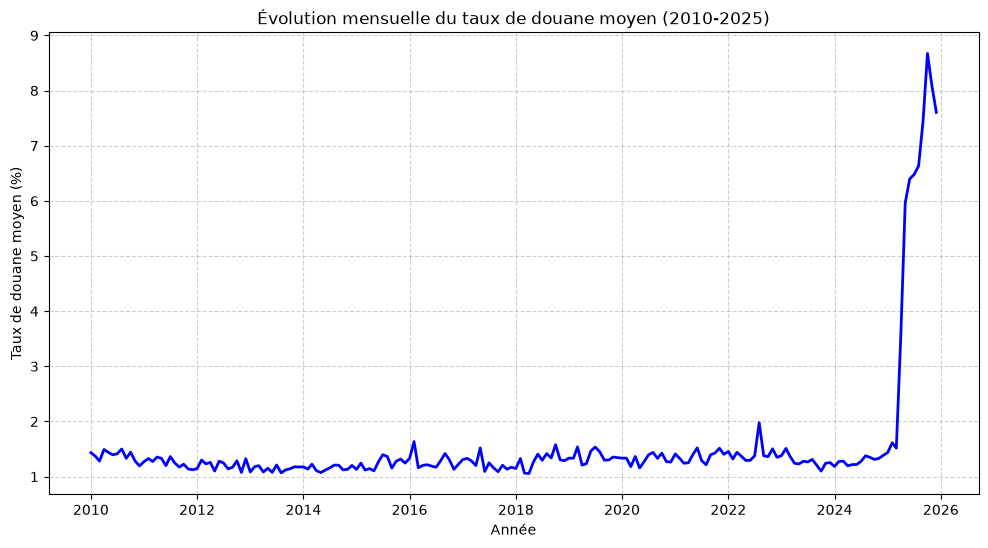

In [7]:

# 8. Evolution temporelle des droits de douane
commerce_usa['time'] = pd.to_datetime(commerce_usa['time'])
commerce_usa_temp = commerce_usa[commerce_usa['douane_pourcentage'] <= 200].groupby('time')['douane_pourcentage'].mean().reset_index()


plt.figure(figsize=(12, 6))
sns.lineplot(data=commerce_usa_temp, x='time', y='douane_pourcentage', color='b', linewidth=2)
plt.title("Évolution mensuelle du taux de douane moyen (2010-2025)")
plt.xlabel("Année")
plt.ylabel("Taux de douane moyen (%)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("evolution_douanes.png", dpi=300, bbox_inches="tight")
print("Graphique sauvegardé avec succès sous 'evolution_douanes.png' !")


Le taux de droits de douane moyen reste stable entre 2010 et 2025, entre 1 et 2%. Il augmente ensuite drastiquement en 2025 et dépasse les 8% pour diminuer légèrement vers la fin de l’année 2025. Il termine à 7,5% environ. 

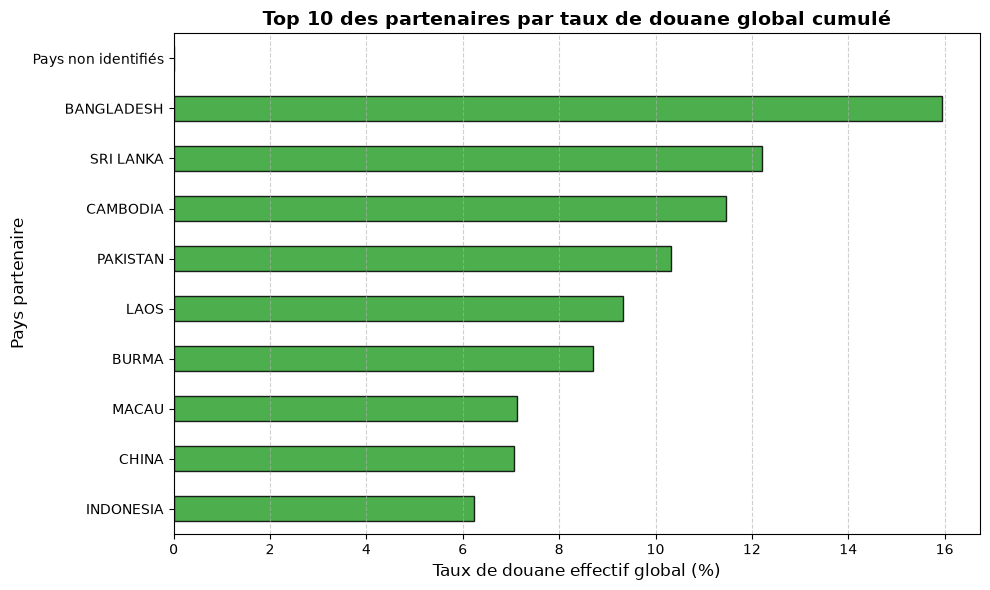

In [8]:
# 9. Top 10 (en ignorant les anomalies > 200 %)
totaux_pays = commerce_usa[commerce_usa['douane_pourcentage'] <= 200].groupby('CTY_NAME')[['droits_douane', 'importations_generales']].sum()
totaux_pays['taux_global'] = (totaux_pays['droits_douane'] / totaux_pays['importations_generales']) * 100

top_10 = totaux_pays['taux_global'].sort_values(ascending=True).tail(10)



plt.figure(figsize=(10, 6))
top_10.plot(kind='barh', color='#2ca02c', edgecolor='black', alpha=0.85)
plt.title("Top 10 des partenaires par taux de douane global cumulé", fontsize=14, fontweight='bold')
plt.xlabel("Taux de douane effectif global (%)", fontsize=12)
plt.ylabel("Pays partenaire", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("top10_taux_douane.png", dpi=300)
plt.show()


Les 10 partenaires avec un taux de droits de douane effectif global sur toute la période comprennent le Bangladesh (première place) ou encore la Chine (en 9ème place). Ce taux varie entre 6 et 16%. L’évolution à travers le temps sera visible sur les cartes interactives dans la suite du rapport. 

### Comparaison entre périodes et test statistique

Enfin, nous comparons les taux de douane effectifs moyens entre la période historique (2010–2024) et la période récente (janvier 2025 – décembre 2025), ainsi que le Top 5 des partenaires sur chaque sous-période. 

La moyenne passe de 1,55 % à 6,61 %, et un test de Student de Welch (equal_var=False) confirme que cette hausse est très significative ($p < 0,001$), notamment sous l'effet des hausses observées avec la Chine (29,73 %), le Bangladesh (23,72 %), l'Azerbaïdjan (23,37 %) et la Birmanie (22,65 %).

Comment cela affecte-t-il les échanges commerciaux ?

In [9]:
# 10. Evolution moyenne des droits de douane : comparaison dans le temps
commerce_usa['time_dt'] = pd.to_datetime(commerce_usa['time'])
commerce_usa['annee'] = commerce_usa['time_dt'].dt.year

commerce_usa_propre = commerce_usa[(commerce_usa['douane_pourcentage'] > 0) & (commerce_usa['douane_pourcentage'] <= 200)].copy()

periode_historique = commerce_usa_propre[commerce_usa_propre['annee'] < 2025]
periode_recente = commerce_usa_propre[commerce_usa_propre['annee'] >= 2025]

print("=" * 65)
print("COMPARAISON DES TAUX DE DOUANE MOYENS ENTRE LES PÉRIODES")
print("=" * 65)
print(f"Moyenne (2010 - 2024) : {periode_historique['douane_pourcentage'].mean():.2f} %")
print(f"Moyenne récente (2025 - 2026) : {periode_recente['douane_pourcentage'].mean():.2f} %")

def calcul_top_periode(sous_commerce_usa, nom_periode):
    totaux = sous_commerce_usa.groupby('CTY_NAME')[['droits_douane', 'importations_generales']].sum()
    totaux['taux'] = (totaux['droits_douane'] / totaux['importations_generales']) * 100
    top = totaux['taux'].sort_values(ascending=False).head(5)
    print(f"\n--- Top 5 des pays ({nom_periode}) ---")
    for pays, taux in top.items():
        print(f"• {pays} : {taux:.2f} %")

calcul_top_periode(periode_historique, "2010-2024")
calcul_top_periode(periode_recente, "2025-2026")

# 11. Test statistique
série_historique = periode_historique['douane_pourcentage']
série_recente = periode_recente['douane_pourcentage']

t_stat, p_value = stats.ttest_ind(série_historique, série_recente, equal_var=False)

print("=" * 65)
print("TEST STATISTIQUE DE COMPARAISON DES MOYENNES (BALANCE CHECK)")
print("=" * 65)
print(f"Moyenne 2010-2024 : {série_historique.mean():.2f} %")
print(f"Moyenne 2025-2026 : {série_recente.mean():.2f} %")
print(f"Statistique t     : {t_stat:.4f}")
print(f"P-value           : {p_value:.4e}")

if p_value < 0.001:
    print("\n Résultat : La différence est TRES SIGNIFICATIVE (p < 0.001).")
else:
    print(f"\n Résultat : P-value = {p_value}")

COMPARAISON DES TAUX DE DOUANE MOYENS ENTRE LES PÉRIODES
Moyenne (2010 - 2024) : 1.55 %
Moyenne récente (2025 - 2026) : 6.61 %

--- Top 5 des pays (2010-2024) ---
• BANGLADESH : 15.18 %
• SRI LANKA : 11.61 %
• CAMBODIA : 10.27 %
• PAKISTAN : 9.60 %
• BURMA : 7.13 %

--- Top 5 des pays (2025-2026) ---
• CHINA : 29.73 %
• BANGLADESH : 23.72 %
• AZERBAIJAN : 23.37 %
• BURMA : 22.65 %
• SRI LANKA : 19.91 %
TEST STATISTIQUE DE COMPARAISON DES MOYENNES (BALANCE CHECK)
Moyenne 2010-2024 : 1.55 %
Moyenne 2025-2026 : 6.61 %
Statistique t     : -33.1920
P-value           : 3.8429e-198

 Résultat : La différence est TRES SIGNIFICATIVE (p < 0.001).


## Création des cartes dynamiques

À partir des données importées dans la partie précédente, nous récupérons le jeu de données `commerce_usa`. Il s'agit de données de panel donnant, mois par mois, la valeur des importations des États-Unis et des droits de douane perçus pour chacun de leurs 236 pays partenaires.

L'objectif est de représenter sous forme de cartes dynamiques les importations et les droits de douane mois par mois pour ces 236 pays.

### Encodage des noms des pays en ISO3

Pour utiliser le package `plotly.express`, il est nécessaire d'encoder le nom des pays partenaires en code ISO3, afin que Plotly puisse automatiquement les placer sur la carte du monde.

Pour ce faire, nous utilisons le package `country_converter`, qui permet d'associer le nom d'un pays à son code ISO3.

In [10]:
logging.getLogger("country_converter.country_converter").setLevel(logging.ERROR) # Supprime les alertes
donnees_cc = pd.read_csv(coco.country_converter.COUNTRY_DATA_FILE, sep="\t", encoding="utf-8",
                         keep_default_na=False, na_values=[""])
cc = coco.CountryConverter(country_data=donnees_cc)

codes_iso3 = {}
for nom in commerce_usa["CTY_NAME"].dropna().unique():
    code = cc.convert(names=nom, to="ISO3")
    
    if isinstance(code, list) or code == "not found":
        print(f"{nom} not found in regex")
        code = pd.NA

    codes_iso3[nom] = (code)

commerce_usa["ISO3"] = commerce_usa["CTY_NAME"].map(codes_iso3) # colonne de noms des pays encodés en ISO3

pays_en_echec = commerce_usa.loc[
    commerce_usa["ISO3"].isna(), "CTY_NAME"
]
print(pays_en_echec.value_counts(dropna=False))

NETHERLANDS ANTILLES not found in regex
GAZA STRIP ADMINISTERED BY ISRAEL not found in regex
WEST BANK ADMINISTERED BY ISRAEL not found in regex


NAOERO not found in regex
Pays non identifiés not found in regex
CTY_NAME
WEST BANK ADMINISTERED BY ISRAEL     192
NAOERO                               192
GAZA STRIP ADMINISTERED BY ISRAEL    186
Pays non identifiés                   40
NETHERLANDS ANTILLES                  24
Name: count, dtype: int64


Nous appliquons les corrections nécessaires aux trois pays qui n'ont pas été reconnus par le package `country_converter`.

In [11]:
corrections = {
    "WEST BANK ADMINISTERED BY ISRAEL": "PSE",
    "GAZA STRIP ADMINISTERED BY ISRAEL": "PSE",
    "NAOERO": "NRU",
    "NETHERLANDS ANTILLES": "ANT",
}

commerce_usa["ISO3"] = commerce_usa["CTY_NAME"].map(corrections).fillna(commerce_usa["ISO3"])

### Cartes dynamiques

Pour créer des cartes dynamiques, nous utilisons le package `plotly`.

La première carte représente, mois par mois depuis 2010, les droits de douane perçus en pourcentage des importations américaines en provenance de chaque pays partenaire.

In [12]:
commerce_usa_anim = commerce_usa.sort_values("time")
fig = px.choropleth(
    commerce_usa_anim,
    locations="ISO3",
    color="douane_pourcentage",
    hover_name="CTY_NAME",
    animation_frame="time",                
    color_continuous_scale="Reds",
    range_color=(0, 20),
    projection="natural earth",
    title="Droits de douane effectifs des États-Unis",
)

fig.write_html("Statistiques descriptives/Cartes/carte_dynamique_douanes.html")        
fig.show(renderer="browser")

La seconde carte dynamique représente, pour chaque mois de 2025, la variation en pourcentage des importations des États-Unis en provenance de chaque pays partenaire par rapport au même mois de 2024.

In [13]:
commerce_usa["date"] = pd.to_datetime(commerce_usa["time"])
commerce_usa["annee"] = commerce_usa["date"].dt.year
commerce_usa["mois"] = commerce_usa["date"].dt.month

# Référence : le même mois en 2024
ref_2024 = (
    commerce_usa[commerce_usa["annee"] == 2024][["CTY_NAME", "mois", "importations_generales"]]
    .rename(columns={"importations_generales": "imports_2024"})
)

commerce_usa_2025 = commerce_usa[commerce_usa["annee"] == 2025].merge(ref_2024, on=["CTY_NAME", "mois"], how="left")
commerce_usa_2025["var_vs_2024"] = (commerce_usa_2025["importations_generales"] / commerce_usa_2025["imports_2024"] - 1) * 100

commerce_usa_anim = commerce_usa_2025.dropna(subset=["ISO3", "var_vs_2024"]).sort_values("date")

fig = px.choropleth(
    commerce_usa_anim,
    locations="ISO3",
    color="var_vs_2024",
    hover_name="CTY_NAME",
    animation_frame="time",
    color_continuous_scale=["darkred", "white", "darkgreen"],
    range_color=(-40, 40),
    projection="natural earth",
    title="Importations des États-Unis (variation par rapport au même mois de 2024, %)",
)
fig.show(renderer="browser")

## Économétrie : DiD

Pour déterminer si les droits de douane imposés par les États-Unis à partir d'avril 2025 ont eu un effet sur les importations, nous testons l'hypothèse suivante :

> **Hypothèse :** après avril 2025, les importations des États-Unis en provenance des pays les plus touchés par les droits de douane ont moins progressé que celles en provenance des pays peu touchés.

Nous considérons comme fortement touché un pays dont le taux moyen de droits de douane a augmenté de plus de 8 points de pourcentage entre la période avril 2024 – mars 2025 et la période avril 2025 – décembre 2025. Nous obtenons ainsi un groupe traité et un groupe témoin.

*Note : plusieurs seuils ont été testés et ne changent pas les conclusions du DiD.*

Enfin, les exportations des petits pays sont très instables d'un mois à l'autre : leurs fortes variations d'importations ou de droits de douane rendraient les estimations peu fiables. Nous restreignons donc l'échantillon aux pays dont les exportations vers les États-Unis ont dépassé en moyenne 1 M$ par mois entre avril 2024 et mars 2025.

In [14]:
df_eco = commerce_usa.copy()

# Moyennes sur l'année avant avril 2025
avant = (
    df_eco[(df_eco["time"] >= "2024-04") & (df_eco["time"] < "2025-04")]
    .groupby(["CTY_NAME", "ISO3"], as_index=False)[["douane_pourcentage", "importations_generales"]]
    .mean()
    .rename(columns={"douane_pourcentage": "douane_moy_avant", "importations_generales": "importations_generales_avant"})
)

# Moyennes après avril 2025
apres = (
    df_eco[(df_eco["time"] >= "2025-04")]
    .groupby(["CTY_NAME", "ISO3"], as_index=False)[["douane_pourcentage", "importations_generales"]]
    .mean()
    .rename(columns={"douane_pourcentage": "douane_moy_apres", "importations_generales": "importations_generales_apres"})
)

# Création du df pour le DiD
df_DiD = avant.merge(apres, on=["CTY_NAME", "ISO3"], how="outer")

# Séparation en groupe traité et groupe témoin
df_DiD["traite"] = (df_DiD["douane_moy_apres"] - df_DiD["douane_moy_avant"] > 8).astype(int)

df_DiD["var_importations_generales"] = ((df_DiD["importations_generales_apres"] - df_DiD["importations_generales_avant"]) / df_DiD["importations_generales_avant"]) * 100

# On enlève les petits pays qui exportent moins de 1 M$/mois vers les États-Unis
df_DiD_filtered = df_DiD[df_DiD["importations_generales_avant"] > 1000000]
print(f'Nombre de pays : {df_DiD_filtered["ISO3"].nunique()} dont {df_DiD_filtered.loc[df_DiD_filtered["traite"] == 1, "ISO3"].nunique()} traités')

Nombre de pays : 170 dont 59 traités


Nous estimons ensuite l'effet par une différence de différences, puis nous vérifions sa significativité à l'aide d'un test de comparaison de moyennes (test de Welch).

In [15]:
# Effet DiD : écart moyen de variation des importations entre pays traités et pays témoins
effet_causal_DiD = df_DiD_filtered[df_DiD_filtered["traite"] == 1]["var_importations_generales"].mean() - df_DiD_filtered[df_DiD_filtered["traite"] == 0]["var_importations_generales"].mean()

# Test de comparaison de moyennes
traites = df_DiD_filtered.loc[df_DiD_filtered["traite"] == 1, "var_importations_generales"].dropna()
temoins = df_DiD_filtered.loc[df_DiD_filtered["traite"] == 0, "var_importations_generales"].dropna()
test = stats.ttest_ind(traites, temoins, equal_var=False)    # equal_var=False = test de Welch

print(f'Effet DiD : {effet_causal_DiD:.2f} points de % (test de Welch : t = {test.statistic:.2f}, p-value = {test.pvalue:.3f})')

Effet DiD : -7.48 points de % (test de Welch : t = -1.12, p-value = 0.262)


### DiD avec contrôles

Pour vérifier la robustesse de notre DiD, nous testons une nouvelle spécification qui ajoute des variables de contrôle sur les pays :

> **Contrôles :** log(PIB), log(PIB par habitant), log(distance aux États-Unis, en km), inflation, superficie, population.

Le PIB, le PIB par habitant, l'inflation et la superficie proviennent de la Banque mondiale, que nous interrogeons via son API :

In [16]:
# Liste des variables complémentaires
indicateurs = {
    "NY.GDP.MKTP.CD": "pib_usd",                          # PIB (USD courants)
    "SP.POP.TOTL": "population",
    "FP.CPI.TOTL.ZG": "inflation",                        # Inflation (%)
    "NY.GDP.PCAP.PP.KD": "pib_hab_ppa",                   # PIB/hab en PPA ($ internationaux constants 2021)
    "AG.SRF.TOTL.K2": "superficie_km2",                   # Superficie (km²)
}

# Téléchargement
wb.per_page = 5000

def telecharger(code, essais=3, pause=10):
    """Télécharge un indicateur. En cas d'erreur du serveur, réessaie jusqu'à 3 fois."""
    for essai in range(1, essais + 1):
        try:
            return wb.data.DataFrame(
                code,
                economy="all",
                time=range(2010, 2026),
                skipAggs=True,
                columns="series",
                numericTimeKeys=True,
            )
        except Exception as erreur:
            tqdm.write(f"   {code} : essai {essai}/{essais} raté ({erreur.__class__.__name__}), "
                       f"nouvel essai dans {pause} s...")
            time.sleep(pause)
    raise RuntimeError(f"Impossible de télécharger {code} après {essais} essais")

morceaux = []
barre = tqdm(indicateurs.items(), total=len(indicateurs), desc="Banque mondiale", unit="indicateur")
debut_total = time.time()

# On importe 1 par 1 chaque indicateur via la fonction telecharger
for code, nom in barre:
    barre.set_postfix_str(nom)      # affiche l'indicateur en cours à droite de la barre
    morceaux.append(telecharger(code).rename(columns={code: nom}))

# On fusionne en un df unique
df_wb = pd.concat(morceaux, axis=1).reset_index()
df_wb = df_wb.rename(columns={"economy": "ISO3", "time": "annee"})
print(f"Banque mondiale terminée en {time.time() - debut_total:.0f} s : {df_wb.shape[0]} lignes")

Banque mondiale:   0%|          | 0/5 [00:00<?, ?indicateur/s, pib_usd]

Banque mondiale: 100%|██████████| 5/5 [00:16<00:00,  3.26s/indicateur, superficie_km2]

Banque mondiale terminée en 16 s : 3472 lignes


Nous utilisons ensuite les données du CEPII pour obtenir la distance aux États-Unis, en km.

In [17]:
# Lecture du fichier Stata directement depuis le site du CEPII
dist = pd.read_stata("https://www.cepii.fr/distance/dist_cepii.dta")

# On garde les paires "USA -> pays partenaire"
dist_usa = dist.loc[dist["iso_o"] == "USA", ["iso_d", "distw"]].rename(
    columns={"iso_d": "ISO3", "distw": "distance_usa_km"}
)

# Le CEPII utilise d'anciens codes pays
correspondances = {
    "ROM": "ROU",   # Roumanie
    "ZAR": "COD",   # RD Congo (ex-Zaïre)
    "TMP": "TLS",   # Timor oriental
    "PAL": "PSE",   # Palestine
    "YUG": "SRB",   # ex-Yougoslavie -> Serbie
}
dist_usa["ISO3"] = dist_usa["ISO3"].replace(correspondances)

# Fusion 
df_wb = df_wb.merge(dist_usa, on="ISO3", how="left")

Nous estimons maintenant le DiD par une régression linéaire, ce qui permet d'introduire des variables de contrôle :

$$
\ln(\text{Imp}_{c,t}) = \alpha + \beta_1 \, \text{Post}_t + \beta_2 \, \text{Traité}_c + \beta_3 \, (\text{Traité}_c \times \text{Post}_t) + X_{c,t}'\gamma + (X_{c,t} \times \text{Post}_t)'\delta + \varepsilon_{c,t}
$$

où $\text{Imp}_{c,t}$ désigne les importations des États-Unis en provenance du pays $c$ sur la période $t$ (avant ou après avril 2025), $\text{Post}_t$ vaut 1 après avril 2025, $\text{Traité}_c$ vaut 1 si le pays appartient au groupe traité, et $X_{c,t}$ regroupe les contrôles : log du PIB, log du PIB par habitant, log de la distance aux États-Unis, inflation et superficie.

Le coefficient d'intérêt est $\beta_3$, l'estimateur DiD. Les termes $X_{c,t} \times \text{Post}_t$ permettent à l'évolution des importations entre les deux périodes de dépendre des caractéristiques des pays : nous comparons ainsi des pays traités et témoins comparables. Les écarts-types sont groupés par pays.

In [18]:
# On ajoute les contrôles (valeurs de 2024, avant le choc) et on passe certaines variables en log
controles = df_wb.loc[df_wb["annee"] == 2024, ["ISO3", "pib_usd", "pib_hab_ppa", "distance_usa_km", "inflation", "superficie_km2", "population"]]
df_DiD_control = df_DiD_filtered.merge(controles, on="ISO3", how="left", validate="m:1")
df_DiD_control["log_pib"] = np.log(df_DiD_control["pib_usd"])
df_DiD_control["log_pib_hab"] = np.log(df_DiD_control["pib_hab_ppa"])
df_DiD_control["log_distance"] = np.log(df_DiD_control["distance_usa_km"])

# On passe au format long (une ligne avant, une ligne après pour chaque pays)
df_long = pd.concat(
    [
        df_DiD_control.assign(post=0, importations_generales=df_DiD_control["importations_generales_avant"]),
        df_DiD_control.assign(post=1, importations_generales=df_DiD_control["importations_generales_apres"]),
    ],
    ignore_index=True,
)
df_long["log_import"] = np.log(df_long["importations_generales"])

# On définit l'ensemble des variables pour l'OLS
variables = ["log_import", "traite", "post", "ISO3", "log_pib", "log_pib_hab", "log_distance", "inflation", "superficie_km2", "population"]
reg = df_long.dropna(subset=variables)
print(f'Il reste {reg["ISO3"].nunique()} pays dont {reg.loc[reg["traite"] == 1, "ISO3"].nunique()} traités')

# On applique l'OLS
did_controles = smf.ols(
    "log_import ~ traite * post + (log_pib + log_pib_hab + log_distance + inflation + superficie_km2 + population) * post",
    data=reg,
).fit(cov_type="cluster", cov_kwds={"groups": reg["ISO3"]})
print(did_controles.summary())

print(f"\nSans contrôles  : effet = {effet_causal_DiD:.2f}, p-value = {test.pvalue:.3f}")
print(f"Avec contrôles  : coef = {did_controles.params['traite:post']:.3f}, p-value = {did_controles.pvalues['traite:post']:.3f}")

Il reste 141 pays dont 50 traités
                            OLS Regression Results                            
Dep. Variable:             log_import   R-squared:                       0.800
Model:                            OLS   Adj. R-squared:                  0.789
Method:                 Least Squares   F-statistic:                     61.01
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.79e-49
Time:                        14:43:34   Log-Likelihood:                -434.45
No. Observations:                 282   AIC:                             900.9
Df Residuals:                     266   BIC:                             959.2
Df Model:                          15                                         
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------


/opt/python/lib/python3.13/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 15, but rank is 12
  res = self.wald_test(


### Résultats

L'échantillon est restreint aux partenaires dont les exportations vers les États-Unis dépassaient en moyenne 1 M$ par mois avant avril 2025, afin d'écarter les petits pays dont les flux sont très volatils.

| Spécification | Effet estimé | p-value |
|---|---|---|
| DiD simple (sans contrôles) | −7,48 points de % | 0,262 |
| DiD par régression (avec contrôles) | +0,056 (≈ +5,6 %) | 0,334 |

*Le premier effet est un écart de variation des importations, en points de pourcentage. Le second est un coefficient sur le log des importations, soit un écart d'environ +5,6 %.*

Dans aucune des deux spécifications l'effet n'est significatif au seuil de 5 %. Les deux estimations sont même de signes opposés, ce qui confirme qu'aucun effet net ne se dégage.

Nous n'observons donc pas d'effet significatif des droits de douane sur les importations des États-Unis **en relatif** : après avril 2025, les importations en provenance des pays les plus touchés n'ont pas évolué différemment de celles en provenance des pays peu touchés. Nos résultats ne mettent pas en évidence d'effet systématique des droits de douane sur les importations. Ils n'excluent pas pour autant des effets importants pour certains pays dont le taux de droits a très fortement augmenté (plus de 30 points), mais ce groupe est trop petit pour en tirer des conclusions générales.

## Conclusion

Dans ce projet, nous avons construit, à partir de l'API du U.S. Census Bureau, une base mensuelle des importations des États-Unis et des droits de douane perçus pour chacun de leurs partenaires entre 2010 et 2025. Le calcul d'un taux de droits de douane effectif confirme la rupture de 2025 : le taux moyen passe de 1,55 % sur 2010–2024 à 6,61 % en 2025, une hausse très significative portée notamment par la Chine. Les cartes dynamiques permettent de suivre cette évolution pays par pays, ainsi que la variation des importations en 2025 par rapport à 2024.

Pour mesurer l'effet de ces hausses sur les importations, nous avons comparé par une différence de différences les partenaires fortement touchés par les droits de douane à ceux qui l'ont été moins, avec et sans contrôles issus de la Banque mondiale et du CEPII. Dans aucune spécification nous ne mettons en évidence d'effet significatif : après avril 2025, les importations en provenance des pays les plus taxés n'ont pas évolué différemment de celles des autres partenaires.

Pour revenir à la question posée en introduction, la flambée des droits de douane de 2025 est donc nette, mais nous ne détectons pas, à court terme, de lien systématique entre l'ampleur de la hausse des droits subie par un partenaire et l'évolution de ses exportations vers les États-Unis. Ce résultat reste à confirmer sur une période plus longue : nos données s'arrêtent en décembre 2025, et le début de l'année  2025 a pu être marqué par des achats anticipés avant l'entrée en vigueur des droits.